<a href="https://colab.research.google.com/github/emammohamedvet-eng/Python-training/blob/main/AI_Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Task 1: Load the Titanic dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import pandas as pd

# Let the user choose the CSV file from their computer
uploaded = files.upload()

# Automatically get the uploaded file name
csv_filename = list(uploaded.keys())[0]

# Load the chosen CSV file
df = pd.read_csv(csv_filename)

# Check that it loaded correctly
df.head()

Saving Titanic-Dataset.csv to Titanic-Dataset (1).csv


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Task 2: Inspect the data
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [5]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Task 3: Clean and preprocess the data

# Create categorical feature for passenger class
df["PclassCategory"] = df["Pclass"].astype("category")

# Create categorical feature for cabin deck
df["CabinCategory"] = df["Cabin"].str[0]
df["CabinCategory"] = df["CabinCategory"].fillna("Unknown")
df["CabinCategory"] = df["CabinCategory"].astype("category")

# Handle missing Age values using the mean age
mean_age = df["Age"].mean()
df["Age"] = df["Age"].fillna(mean_age)

# Create Family feature
df["Family"] = df["SibSp"] + df["Parch"]

df[["PclassCategory", "CabinCategory", "Age", "Family"]].head()

,PclassCategory,CabinCategory,Age,Family
0,3,Unknown,22.0,1
1,1,C,38.0,1
2,3,Unknown,26.0,0
3,1,C,35.0,1
4,3,Unknown,35.0,0


In [8]:
# Task 4: Identify specific data points

highest_fare_passengers = df[df["Fare"] == df["Fare"].max()]
highest_fare_passengers

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,PclassCategory,CabinCategory,Family
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C,1,Unknown,0
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C,1,B,1
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C,1,B,0


In [9]:
largest_family_passengers = df[df["Family"] == df["Family"].max()]
largest_family_passengers

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,PclassCategory,CabinCategory,Family
159,160,0,3,"Sage, Master. Thomas Henry",male,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10
180,181,0,3,"Sage, Miss. Constance Gladys",female,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10
201,202,0,3,"Sage, Mr. Frederick",male,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10
324,325,0,3,"Sage, Mr. George John Jr",male,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10
792,793,0,3,"Sage, Miss. Stella Anna",female,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10
846,847,0,3,"Sage, Mr. Douglas Bullen",male,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,29.699118,8,2,CA. 2343,69.55,NaN,S,3,Unknown,10


In [10]:
# Task 5: Demonstrate Pandas Series and DataFrame functionalities

# Create a Series of passenger names
names_series = df["Name"]
print(type(names_series))
names_series.head()

<class 'pandas.core.series.Series'>


,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"


In [11]:
# Create a DataFrame of passenger names and ages
names_ages_df = df[["Name", "Age"]]
names_ages_df.head()

,Name,Age
0,"Braund, Mr. Owen Harris",22.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
2,"Heikkinen, Miss. Laina",26.0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0
4,"Allen, Mr. William Henry",35.0


In [12]:
# Slice the DataFrame to show only passengers older than 50
older_passengers = df[df["Age"] > 50][["Name", "Age", "Sex", "Pclass"]]
older_passengers.head()

,Name,Age,Sex,Pclass
6,"McCarthy, Mr. Timothy J",54.0,male,1
11,"Bonnell, Miss. Elizabeth",58.0,female,1
15,"Hewlett, Mrs. (Mary D Kingcome)",55.0,female,2
33,"Wheadon, Mr. Edward H",66.0,male,2
54,"Ostby, Mr. Engelhart Cornelius",65.0,male,1


In [13]:
df.iloc[0:5, 0:5]

,PassengerId,Survived,Pclass,Name,Sex
0,1,0,3,"Braund, Mr. Owen Harris",male
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female
2,3,1,3,"Heikkinen, Miss. Laina",female
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female
4,5,0,3,"Allen, Mr. William Henry",male


In [14]:
# Task 6: Multi-indexing

multi_index_df = (
    df.groupby(["Sex", "Pclass"])["Survived"]
    .mean()
    .to_frame(name="SurvivalRate")
)

multi_index_df

SurvivalRate
Sex    Pclass              
female 1           0.968085
       2           0.921053
       3           0.500000
male   1           0.368852
       2           0.157407
       3           0.135447

In [15]:
multi_index_df.unstack()

SurvivalRate                    
Pclass            1         2         3
Sex                                    
female     0.968085  0.921053  0.500000
male       0.368852  0.157407  0.135447

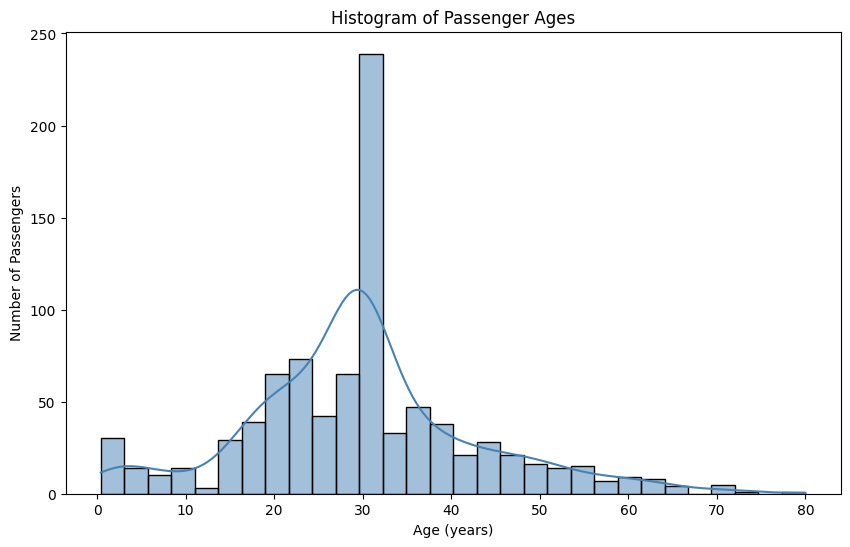

In [16]:
# Task 7: Histogram of passenger ages
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="Age", bins=30, kde=True, color="steelblue")
plt.title("Histogram of Passenger Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.show()

/tmp/ipykernel_741/4023442951.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=survival_by_class, x="Pclass", y="Survived", palette="viridis")


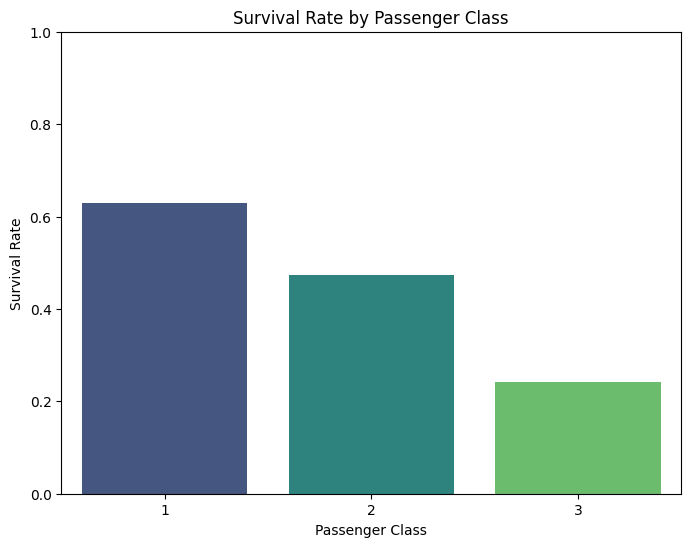

In [17]:
# Bar plot of survival rates by passenger class
survival_by_class = df.groupby("Pclass")["Survived"].mean().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(data=survival_by_class, x="Pclass", y="Survived", palette="viridis")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.show()

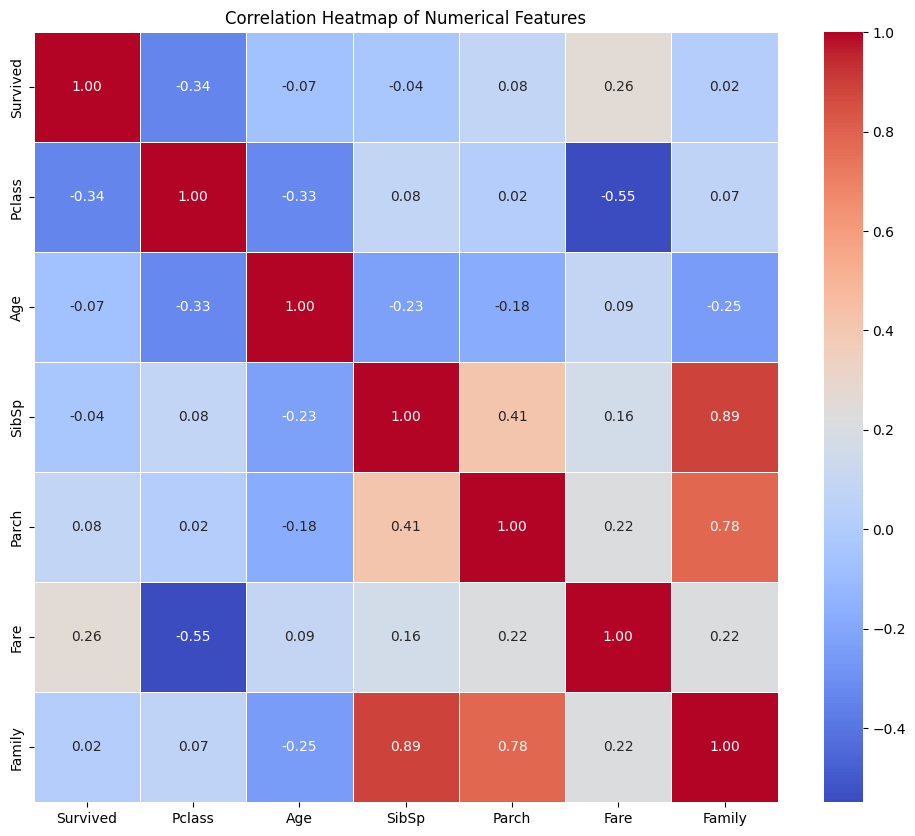

In [18]:
# Correlation heatmap
numeric_columns = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Family"]
correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

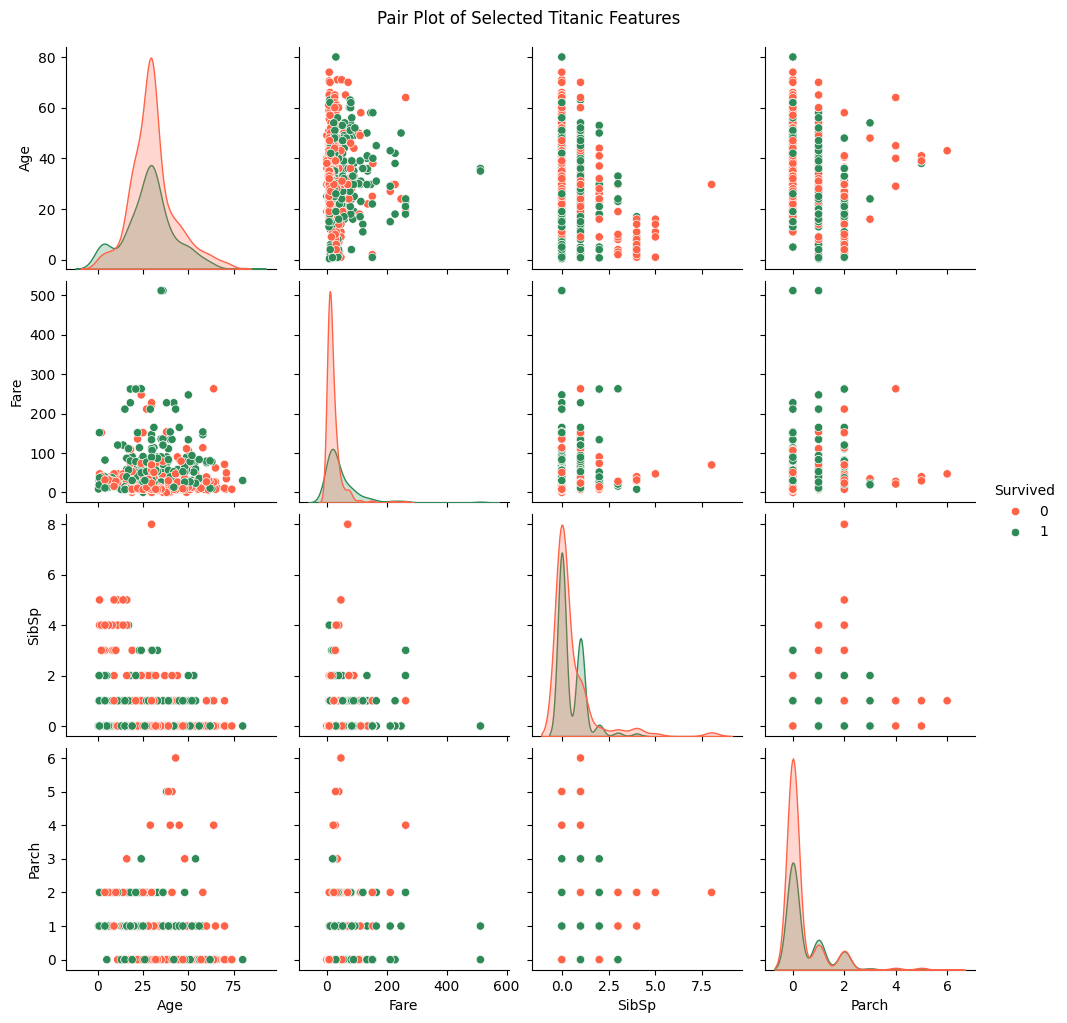

In [19]:
# Pair plot of selected features
selected_features = ["Age", "Fare", "SibSp", "Parch", "Survived"]

sns.pairplot(
    df[selected_features],
    hue="Survived",
    palette={0: "tomato", 1: "seagreen"},
    diag_kind="kde"
)
plt.suptitle("Pair Plot of Selected Titanic Features", y=1.02)
plt.show()

In [20]:
# Task 8: Analyze survival rates

survival_by_sex = df.groupby("Sex")["Survived"].mean()
survival_by_sex

,Survived
Sex,
female,0.742038
male,0.188908


In [21]:
survival_by_class = df.groupby("Pclass")["Survived"].mean()
survival_by_class

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


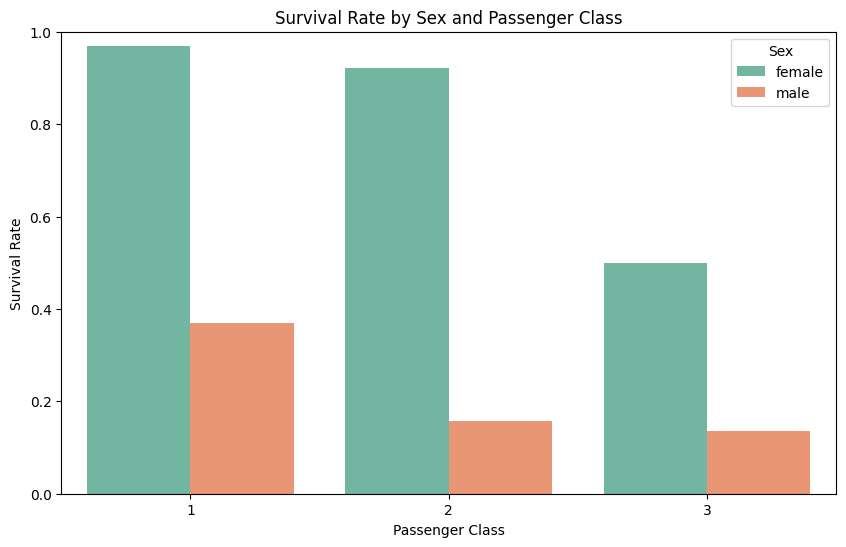

In [22]:
survival_by_sex_and_class = (
    df.groupby(["Sex", "Pclass"])["Survived"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=survival_by_sex_and_class,
    x="Pclass",
    y="Survived",
    hue="Sex",
    palette="Set2"
)
plt.title("Survival Rate by Sex and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.legend(title="Sex")
plt.show()

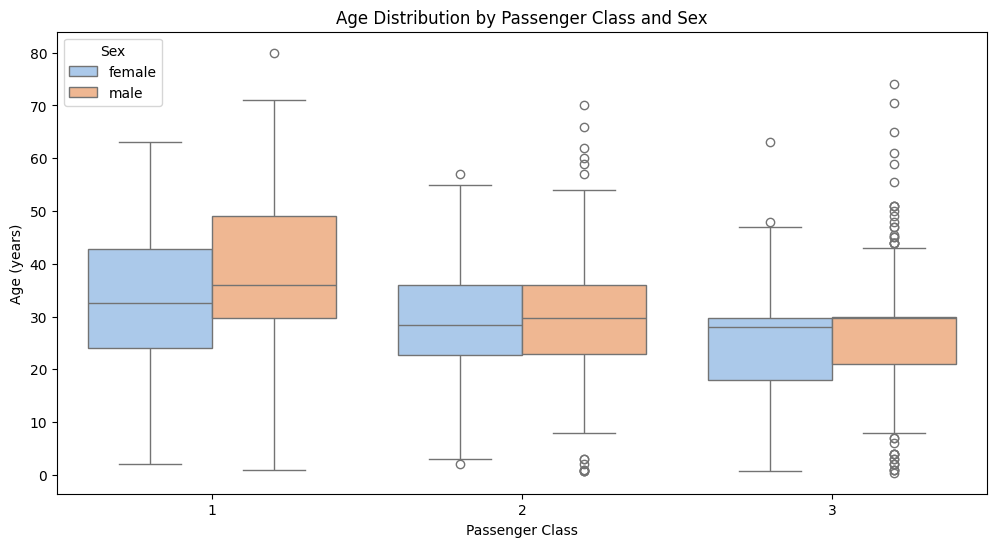

In [23]:
# Task 9: Box plot of age distribution
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="Pclass",
    y="Age",
    hue="Sex",
    palette="pastel"
)
plt.title("Age Distribution by Passenger Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Age (years)")
plt.legend(title="Sex")
plt.show()

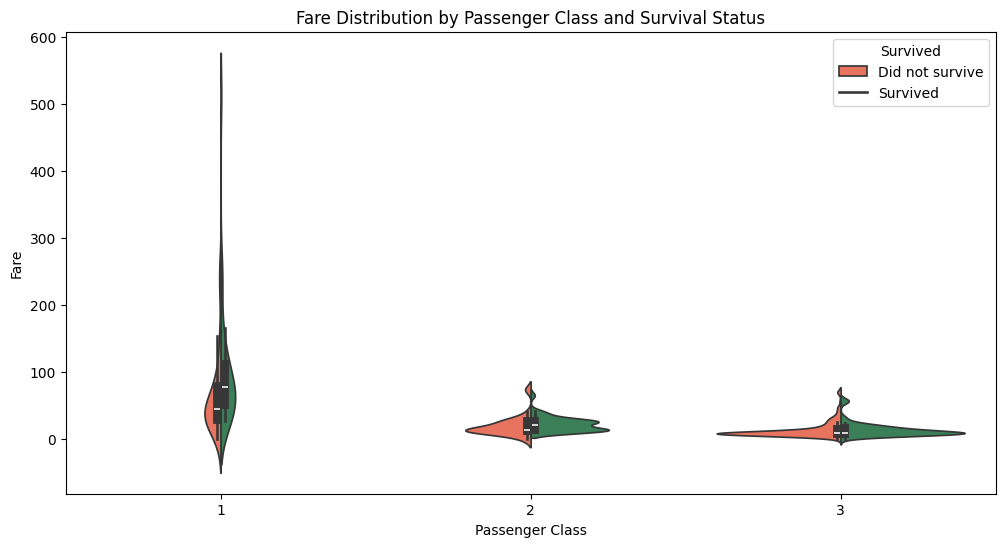

In [24]:
# Task 10: Violin plot of fare distribution
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df,
    x="Pclass",
    y="Fare",
    hue="Survived",
    split=True,
    palette={0: "tomato", 1: "seagreen"}
)
plt.title("Fare Distribution by Passenger Class and Survival Status")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.legend(title="Survived", labels=["Did not survive", "Survived"])
plt.show()

In [25]:
print("EDA tasks completed.")

EDA tasks completed.


Overall EDA insights

The Titanic dataset contains 891 passengers, with missing values mainly in Age, Cabin, and Embarked.

Missing ages were handled by replacing them with the mean age, allowing age-based visualisations to be created.

Most passengers were between 20 and 40 years old, and the age distribution was right-skewed.

Survival was strongly related to sex: females survived at a much higher rate than males.

Survival was also related to passenger class: first-class passengers had the highest survival rate, while third-class passengers had the lowest.

Higher fares were associated with higher survival rates, likely because fare was related to passenger class and cabin location.

Family size varied widely; the Sage family had the largest recorded family size of 10.

The highest fare was 512.33, paid by Anna Ward, a first-class passenger.

Overall, the EDA suggests that sex, passenger class, fare, and age were important factors associated with Titanic survival